# Aula 1 — Tempo 2
## De onde vem uma previsão de falha?

**TE-292 — Ciência de Dados para Operação e Manutenção de Aeronaves**

---

Este notebook abre a disciplina com um caso concreto: uma máquina industrial monitorada por sensores, com falhas registradas.

**Não vamos treinar nenhum modelo hoje.** Vamos apenas *olhar para o dado*.

A pergunta que guia a aula é:

> Quanto de um problema de manutenção preditiva dá para resolver **antes** de chamar aprendizado de máquina?

A resposta vai ser surpreendente — e vai definir o que faremos nas próximas 16 aulas.

## 1. A base

`AI4I 2020 Predictive Maintenance Dataset` — registros de operação de uma fresadora, com temperatura, rotação, torque e desgaste de ferramenta.

Usamos uma máquina industrial, e não uma aeronave, por um motivo prático: é uma base pequena, pública e bem documentada. A estrutura do problema — sensores, degradação, modos de falha, evento raro — é exatamente a mesma que veremos em motores aeronáuticos a partir da aula 7.


Primeiramente, vamos verificar onde o Jupyter Lab está instalado.

In [60]:
import sys, platform
print(platform.python_version(), sys.executable)

3.12.3 /home/celio/.local/share/pipx/venvs/jupyterlab/bin/python


Agora instalamos algumas dependências.

In [61]:
!pipx inject jupyterlab numpy pandas matplotlib seaborn scikit-learn scipy

  injected package numpy into venv jupyterlab
done! ✨ 🌟 ✨
  injected package pandas into venv jupyterlab
done! ✨ 🌟 ✨
  injected package matplotlib into venv jupyterlab
done! ✨ 🌟 ✨
  injected package seaborn into venv jupyterlab
done! ✨ 🌟 ✨
  injected package scikit-learn into venv jupyterlab
done! ✨ 🌟 ✨
  injected package scipy into venv jupyterlab
done! ✨ 🌟 ✨


In [62]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/ai4i2020.csv", encoding="utf-8-sig")
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


> **Nota técnica.** O `encoding="utf-8-sig"` não é decoração. O arquivo começa com um caractere invisível (BOM) que, sem esse argumento, gruda no nome da primeira coluna e transforma `UDI` em `\ufeffUDI`. Você perderia dez minutos procurando o erro. Detalhes assim são metade do trabalho real com dados.

In [63]:

df = df.rename(columns={
    'Air temperature [K]'    : 'air_temp_k',
    'Process temperature [K]': 'process_temp_k',
    'Rotational speed [rpm]' : 'speed_rpm',
    'Torque [Nm]'            : 'torque_nm',
    'Tool wear [min]'        : 'tool_wear_min',
    'Machine failure'        : 'failures',
    'TWF': 'tool_wear_f',
    'HDF': 'heat_diss_f',
    'PWF': 'power_f',
    'OSF': 'overstrain_f',
    'RNF': 'random_f',
})

print(f"Registros : {df.shape[0]:,}")
print(f"Colunas   : {df.shape[1]}")

Registros : 10,000
Colunas   : 14


In [64]:
df.head(3)

,UDI,Product ID,Type,air_temp_k,process_temp_k,speed_rpm,torque_nm,tool_wear_min,failures,tool_wear_f,heat_diss_f,power_f,overstrain_f,random_f
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


### Pergunta de partida: o que é *uma linha*?

Antes de qualquer estatística, é preciso saber a que corresponde um registro. Aqui, cada linha é **uma peça produzida** — não uma máquina, não um dia de operação, não um voo.

Isso determina tudo o que vem depois. Se a granularidade estiver errada na sua cabeça, toda análise subsequente estará errada também.

In [65]:
print(f"Celulas vazias    : {df.isna().sum().sum()}")
print(f"Linhas duplicadas : {df.duplicated().sum()}")
print(f"UDI unicos        : {df['UDI'].nunique():,}")
print(f"Product ID unicos : {df['Product ID'].nunique():,}")

Celulas vazias    : 0
Linhas duplicadas : 0
UDI unicos        : 10,000
Product ID unicos : 10,000


Zero faltantes, zero duplicatas, identificadores perfeitamente únicos.

**Isto é bom demais para ser verdade** — e é mesmo: a base é semissintética, gerada a partir de um modelo. Dados reais de manutenção chegam com campo em branco, data invertida, unidade trocada e a mesma ordem de serviço lançada duas vezes.

## 2. As variáveis de processo

In [66]:
PROCESS_COLUMNS = [
    'air_temp_k',
    'process_temp_k',
    'speed_rpm',
    'torque_nm',
    'tool_wear_min',
    'failures',
]
df[PROCESS_COLUMNS].describe().round(2)

,air_temp_k,process_temp_k,speed_rpm,torque_nm,tool_wear_min,failures
count,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95,0.03
std,2.0,1.48,179.28,9.97,63.65,0.18
min,295.3,305.70,1168.00,3.80,0.00,0.00
25%,298.3,308.80,1423.00,33.20,53.00,0.00
50%,300.1,310.10,1503.00,40.10,108.00,0.00
75%,301.5,311.10,1612.00,46.80,162.00,0.00
max,304.5,313.80,2886.00,76.60,253.00,1.00


Cinco grandezas físicas. Note que `Tool wear` vai de 0 a 253 minutos: é a única que **acumula** ao longo do tempo. As outras quatro são medidas instantâneas.

Essa distinção entre *estado instantâneo* e *dano acumulado* é o embrião do conceito de **vida útil remanescente (RUL)**, que estruturará as aulas 7 e 8.

## 3. O evento que interessa

Agora a variável central: a máquina falhou?

In [67]:
n_failures = int(df["failures"].sum())
failure_rate = 100 * df["failures"].mean()

print(f"Falhas: {n_failures} de {len(df):,}  ({failure_rate:.2f}%)")
print(f"Um modelo que responda 'nunca falha' acerta {100 - failure_rate:.2f}% das vezes.")

Falhas: 339 de 10,000  (3.39%)
Um modelo que responda 'nunca falha' acerta 96.61% das vezes.


### Pare aqui e discuta

Um modelo que **sempre** responde *"não vai falhar"* tem **96,61% de acurácia** — e é completamente **inútil**. Nunca previu uma falha sequer.

Este é o primeiro resultado importante da disciplina, e ele veio de uma única linha de código:

> **Em manutenção, o evento que interessa é raro. Acurácia é uma métrica enganosa.**

Voltaremos a isso com todo o rigor na aula 11. Por ora, guarde a intuição.

In [68]:
df.groupby("Type")["failures"].agg(lambda s: f"{len(s)} linhas, {s.sum()} falhas")

Type
H     1003 linhas, 21 falhas
L    6000 linhas, 235 falhas
M     2997 linhas, 83 falhas
Name: failures, dtype: str

In [69]:
by_type = df.groupby("Type")["failures"].agg(
    n="size",
    failures="sum",
    failure_rate_pct=lambda s: round(100 * s.mean(), 2),
)
by_type = by_type.reindex(["L", "M", "H"])
by_type

,n,failures,failure_rate_pct
Type,,,
L,6000,235,3.92
M,2997,83,2.77
H,1003,21,2.09


`Type` é a qualidade do produto: **L**ow, **M**edium, **H**igh. Produtos de baixa qualidade falham quase o dobro dos de alta (3,92% contra 2,09%).

Uma variável categórica simples já carrega sinal — e sem nenhum modelo.

## 4. Cinco modos de falha

`Machine failure` é um resumo. A base também registra **como** a máquina falhou:

| Identificador | Significado |
|---|---|
| `tool_wear_f` | *Tool Wear Failure* — falha por desgaste de ferramenta |
| `heat_diss_f` | *Heat Dissipation Failure* — falha de dissipação de calor |
| `power_f` | *Power Failure* — falha de potência |
| `overstrain_f` | *Overstrain Failure* — falha por sobrecarga |
| `random_f` | *Random Failure* — falha aleatória |

In [70]:
MODES = ["tool_wear_f", "heat_diss_f", "power_f", "overstrain_f", "random_f"]
mode_counts = df[MODES].sum().sort_values(ascending=False)
print(mode_counts.to_string())
print(f"\nSoma dos modos : {mode_counts.sum()}")
print(f"Machine failure: {n_failures}")

heat_diss_f     115
overstrain_f     98
power_f          95
tool_wear_f      46
random_f         19

Soma dos modos : 373
Machine failure: 339


**373 ≠ 339.** As contas não fecham. Por quê?

Deixe os alunos levantarem hipóteses antes de rodar a próxima célula.

In [71]:
FOUR_MODES = ["tool_wear_f", "heat_diss_f", "power_f", "overstrain_f"]
df["n_modes"] = df[FOUR_MODES].sum(axis=1)

print("Modos simultaneos por registro:")
print("-----")
print(df["n_modes"].value_counts().sort_index().to_string())
print("-----")

no_mode_failures = df[(df["failures"] == 1) & (df["n_modes"] == 0) & (df["random_f"] == 0)]
random_without_failure = df[(df["random_f"] == 1) & (df["failures"] == 0)]

print(f"\nFalha declarada, nenhum modo marcado : {len(no_mode_failures)}")
print(f"Random marcado, mas Machine failure = 0 : {len(random_without_failure)}")

Modos simultaneos por registro:
-----
n_modes
0    9670
1     307
2      22
3       1
-----

Falha declarada, nenhum modo marcado : 9
Random marcado, mas Machine failure = 0 : 18


Três descobertas, todas relevantes:

1. **23 registros têm mais de um modo simultâneo** (22 com dois, 1 com três). Falhas não são mutuamente exclusivas — o que impede tratar isso como uma classificação simples de cinco categorias.
2. **9 registros declaram falha sem nenhum modo marcado.** O rótulo se contradiz.
3. **18 registros têm `Random = 1` mas `Machine failure = 0`.** A "falha aleatória" não foi contada como falha da máquina.

Ou seja: **até o rótulo — a suposta verdade do problema — tem inconsistência.** Numa base curada e publicada. Em dados reais de manutenção, isso é a regra, não a exceção.

> Decidir o que fazer com esses 27 registros é uma decisão de engenharia, não de estatística. E ela precisa ser tomada e documentada antes de qualquer modelo.

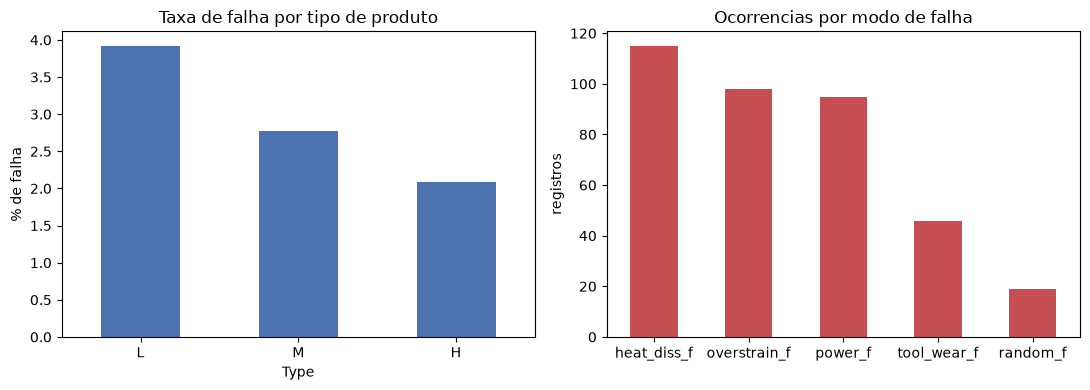

In [72]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

by_type["failure_rate_pct"].plot.bar(ax=ax[0], color="#4C72B0", rot=0)
ax[0].set_title("Taxa de falha por tipo de produto")
ax[0].set_ylabel("% de falha")
ax[0].set_xlabel("Type")

mode_counts.plot.bar(ax=ax[1], color="#C44E52", rot=0)
ax[1].set_title("Ocorrencias por modo de falha")
ax[1].set_ylabel("registros")

fig.tight_layout()

---

## 5. A virada: e se o dado já contiver a resposta?

Até aqui, contamos e descrevemos. Agora vamos usar **física elementar**.

Potência mecânica é torque vezes velocidade angular:

$$P = \tau \cdot \omega = \text{torque\_nm} \cdot \frac{2\pi \cdot \text{speed\_rpm}}{60}$$

Essa coluna não existe na base. Vamos criá-la.

In [73]:
df["mec_power_w"] = df["torque_nm"] * df["speed_rpm"] * 2 * np.pi / 60
df["mec_power_w"].describe().round(0)

count    10000.0
mean      6280.0
std       1067.0
min       1148.0
25%       5561.0
50%       6271.0
75%       7003.0
max      10470.0
Name: mec_power_w, dtype: float64

A potência varia de cerca de 1.150 a 10.470 W. Vamos testar uma suspeita: será que `power_f` (falha de potência) acontece nos extremos dessa faixa?

In [74]:
power_rule = (df["mec_power_w"] < 3500) | (df["mec_power_w"] > 9000)
pd.crosstab(power_rule, df["power_f"], rownames=["rule"], colnames=["power_f"])

power_f,0,1
rule,,
False,9905,0
True,0,95


### Leia essa tabela com atenção

**Zero erros.** A diagonal é perfeita: 9.905 registros dentro da faixa e sem Power, 95 fora da faixa e todos com Power.

`Mechanical Power` **não é um fenômeno a prever** — é uma regra determinística: *potência fora de 3.500 a 9.000 W*. Descobrimos isso com uma multiplicação e uma tabela cruzada.

Nenhum modelo de aprendizado de máquina faria melhor. Nem poderia: 100% já é o teto.

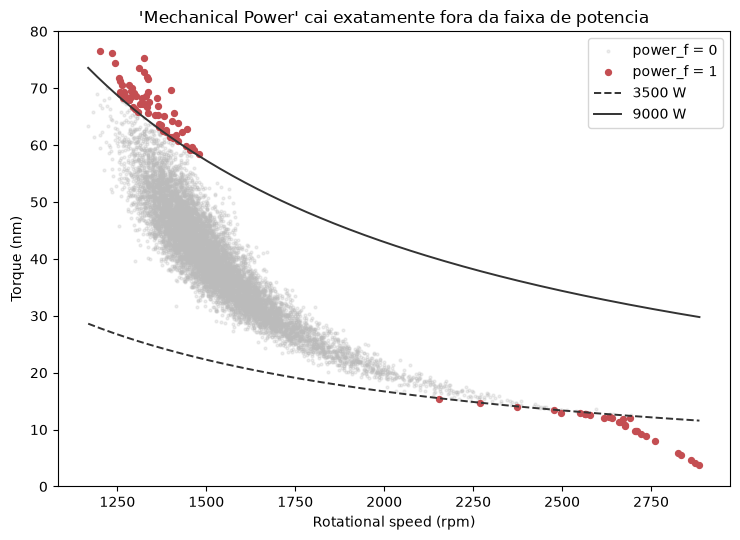

In [75]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))

ok = df["power_f"] == 0
ax.scatter(df.loc[ok, "speed_rpm"], df.loc[ok, "torque_nm"],
           s=4, alpha=0.25, color="#BBBBBB", label="power_f = 0")
ax.scatter(df.loc[~ok, "speed_rpm"], df.loc[~ok, "torque_nm"],
           s=18, color="#C44E52", label="power_f = 1")

rpm = np.linspace(df["speed_rpm"].min(), df["speed_rpm"].max(), 200)
for limit, style in [(3500, "--"), (9000, "-")]:
    ax.plot(rpm, limit / (rpm * 2 * np.pi / 60), style, color="#333333", lw=1.4,
            label=f"{limit} W")

ax.set_xlabel("Rotational speed (rpm)")
ax.set_ylabel("Torque (nm)")
ax.set_ylim(0, 80)
ax.set_title("'Mechanical Power' cai exatamente fora da faixa de potencia")
ax.legend()
fig.tight_layout()

**Este é o gráfico central da aula.**

Os pontos vermelhos ficam todos acima da curva superior ou abaixo da inferior. As duas curvas são hipérboles $\tau = P/\omega$ — não foram ajustadas a nada, saíram da física.

A fronteira de decisão estava no dado o tempo inteiro. Bastou escolher os eixos certos.

### Sua vez: repita o raciocínio para heat_diss_f

`heat_diss_f` é falha de dissipação de calor. Duas ideias plausíveis:

- a diferença entre temperatura de processo e do ar é pequena demais (dissipa mal);
- a rotação é baixa demais (ventilação insuficiente).

Os limiares abaixo são 8,6 K e 1.380 rpm.

In [76]:
df["delta_k"] = df["process_temp_k"] - df["air_temp_k"]

heat_diss_rule = (df["delta_k"] < 8.6) & (df["speed_rpm"] < 1380)
pd.crosstab(heat_diss_rule, df["heat_diss_f"], rownames=["rule"], colnames=["heat_diss_f"])

heat_diss_f,0,1
rule,,
False,9885,0
True,0,115


De novo, **115 de 115, sem um único erro**.

### E para Overstrain

`Overstrain` é falha por sobrecarga. A intuição: o produto entre desgaste da ferramenta e torque ultrapassa um limite — que depende da qualidade do produto.

In [77]:
THRESHOLD = {"L": 11000, "M": 12000, "H": 13000}

df["wear_torque_product"] = df["tool_wear_min"] * df["torque_nm"]
overstrain_rule = df["wear_torque_product"] > df["Type"].map(THRESHOLD)

pd.crosstab(overstrain_rule, df["overstrain_f"], rownames=["rule"], colnames=["overstrain_f"])

overstrain_f,0,1
rule,,
False,9902,0
True,0,98


**98 de 98.** Três modos de falha, três regras exatas.

---

## 6. Onde a análise para de funcionar

Se três modos são determinísticos, o quarto também deveria ser. `ToolWear` é falha por desgaste — e temos a coluna de desgaste.

As 46 ocorrências de `ToolWear` estão todas entre 198 e 253 minutos de desgaste. Então basta a regra *desgaste ≥ 198*, certo?

In [ ]:
high_wear = df[df["tool_wear_min"] >= 198]

print(f"Registros com desgaste >= 198 min : {len(high_wear):,}")
print(f"Destes, com ToolWear = 1               : {int(high_wear['tool_wear_f'].sum())}")
print(f"Proporcao                         : {100 * high_wear['tool_wear_f'].mean():.1f}%")

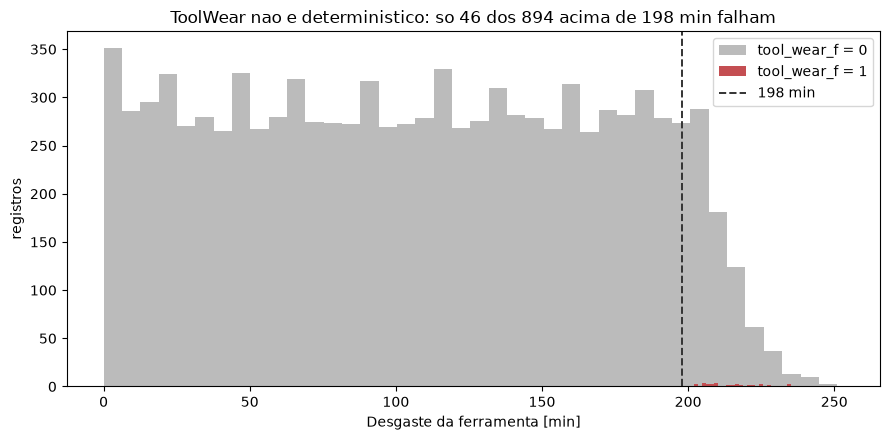

In [79]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.hist(df.loc[df["tool_wear_f"] == 0, "tool_wear_min"], bins=40, color="#BBBBBB", label="tool_wear_f = 0")
ax.hist(df.loc[df["tool_wear_f"] == 1, "tool_wear_min"], bins=40, color="#C44E52", label="tool_wear_f = 1")
ax.axvline(198, color="#333333", ls="--", lw=1.4, label="198 min")

ax.set_xlabel("Desgaste da ferramenta [min]")
ax.set_ylabel("registros")
ax.set_title("ToolWear nao e deterministico: so 46 dos 894 acima de 198 min falham")
ax.legend()
fig.tight_layout()

### O contraste que define a disciplina

A regra *desgaste ≥ 198* pega **894 registros** para capturar **46 falhas**. Errararia 848 vezes — uma taxa de acerto de 5,1%.

Desgaste alto é **condição necessária, não suficiente**. `ToolWear` é um fenômeno *estocástico*: a ferramenta pode falhar naquela faixa, mas normalmente não falha.

E `Random`, por definição, é ruído puro — 19 casos sem qualquer estrutura.

> **É exatamente aqui que o aprendizado de máquina entra.**
>
> Não para redescobrir a fórmula da potência — para isso, física e uma tabela cruzada bastam, e são melhores, porque são auditáveis e explicáveis.
>
> ML serve para os casos em que **não existe regra conhecida**, o fenômeno é probabilístico e o sinal está espalhado por muitas variáveis ao mesmo tempo.

## 7. Fechamento

In [80]:
explained_failures = int((df["power_f"] | df["heat_diss_f"] | df["overstrain_f"]).sum())

summary = pd.DataFrame({
    "mode": ["power_f", "heat_diss_f", "overstrain_f", "tool_wear_f", "random_f"],
    "cases": [95, 115, 98, 46, 19],
    "rule": [
        "potencia fora de [3500, 9000] W",
        "Delta T < 8.6 K e rotacao < 1380 rpm",
        "desgaste x torque > limiar do Type",
        "desgaste alto, mas so 5% dos casos",
        "nenhuma",
    ],
    "deterministic": ["yes", "yes", "yes", "no", "no"],
})

print(summary.to_string(index=False))
print(f"\nFalhas cobertas por regra exata: {explained_failures} de {n_failures}"
      f"  ({100 * explained_failures / n_failures:.0f}%)")

        mode  cases                                 rule deterministic
     power_f     95      potencia fora de [3500, 9000] W           yes
 heat_diss_f    115 Delta T < 8.6 K e rotacao < 1380 rpm           yes
overstrain_f     98   desgaste x torque > limiar do Type           yes
 tool_wear_f     46   desgaste alto, mas so 5% dos casos            no
    random_f     19                              nenhuma            no

Falhas cobertas por regra exata: 287 de 339  (85%)


### O que aconteceu nesta aula

Sem treinar um único modelo, apenas olhando para o dado, nós:

- estabelecemos a granularidade do registro;
- descobrimos que o evento de interesse é raro (3,39%) e que **acurácia engana**;
- encontramos **inconsistência no próprio rótulo** (27 registros);
- construímos uma variável física que não existia na base (potência);
- explicamos **85% das falhas** com três regras determinísticas e auditáveis;
- isolamos exatamente **onde** a regra falha e o aprendizado de máquina se torna necessário.

> **A lição da aula 1:** a análise de dados não é uma etapa preliminar que se atravessa depressa para chegar ao modelo. Ela é que decide **se** o modelo é necessário, **onde** ele é necessário e **contra o que** ele terá de ser comparado.
>
> Um modelo que não supera uma regra de três linhas não deveria ser colocado em produção.

### O caminho daqui

| Aula | O que aprofunda deste notebook |
|---|---|
| 2 | Que política de manutenção cada tipo de falha exige |
| 3 | De onde vêm esses dados e como integrá-los |
| 5 | Dados que **não** chegam limpos |
| 6 | Análise exploratória com rigor e método |
| 7-8 | Degradação, RUL e construção de variáveis como a potência |
| 9-10 | Os modelos, finalmente — com esta regra como linha de base a superar |
| 11 | Por que 96,61% de acurácia é um resultado ruim |

---

## Exercício para casa

1. Os 9 registros com `failures = 1` e nenhum modo marcado: você os descartaria, corrigiria ou manteria? Escreva um parágrafo justificando — a decisão é de engenharia, e precisa ser defensável.
2. Os 18 registros com `random_f = 1` e `failures = 0` sugerem que a falha aleatória foi excluída do rótulo principal. Isso é razoável? O que muda se você incluí-la?
3. Existe algum registro que a regra de potência classificaria como falha e que **não** está marcado como `failures`? Investigue e explique.

---

## Resolução — pergunta 1

*Os 9 registros com `failures = 1` e nenhum modo marcado: descartar, corrigir ou manter?*

Primeiro, vamos olhar para esses registros diretamente — sem eles, a discussão vira opinião sem dado.

In [22]:
cols = ["UDI", "Type", "air_temp_k", "process_temp_k", "speed_rpm", "torque_nm", "tool_wear_min"]
print(no_mode_failures[cols].to_string(index=False))
print(f"\nn = {len(no_mode_failures)} de {n_failures} falhas totais ({100 * len(no_mode_failures) / n_failures:.1f}%)")

 UDI Type  air_temp_k  process_temp_k  speed_rpm  torque_nm  tool_wear_min
1438    H       298.8           309.9       1439       45.2             40
2750    M       299.7           309.2       1685       28.9            179
4045    M       301.9           310.9       1419       47.7             20
4685    M       303.6           311.8       1421       44.8            101
5537    M       302.3           311.8       1363       54.0            119
5942    L       300.6           310.7       1438       48.5             78
6479    L       300.5           309.8       1663       29.1            145
8507    L       298.4           309.6       1710       27.3            163
9016    L       297.2           308.1       1431       49.7            210

n = 9 de 339 falhas totais (2.7%)


Nenhum desses 9 casos bate com as três regras determinísticas da seção 5 (potência, dissipação de calor, sobrecarga) — não é que a regra "esqueceu" de marcar o modo; os valores de fato não cruzam nenhum limiar conhecido.

**Recomendação: manter, com um rótulo explícito de "causa não classificada"** — não descartar, não forçar uma correção. Três razões:

- `failures` é a variável-alvo (o evento físico observado); os cinco modos são metadados de diagnóstico. Descartar a linha porque o diagnóstico está incompleto joga fora o evento em si — e a classe positiva já é rara (339 casos). Perder 9 delas por um problema de rotulagem de *causa*, não de *ocorrência*, é caro e não se justifica.
- "Corrigir" (atribuir manualmente um dos quatro modos) exigiria uma regra sem sustentação nos dados: nenhum dos limiares da aula bate com esses 9 casos. Forçar um rótulo aqui é trocar uma inconsistência conhecida por um erro silencioso.
- Manter como "falha, modo desconhecido" preserva o que se sabe (houve falha) sem inventar o que não se sabe (por quê) — e isso é documentável e defensável perante auditoria, ao contrário de apagar ou remarcar silenciosamente.

---

## Resolução — pergunta 2

*Os 18 registros com `random_f = 1` e `failures = 0`: isso é razoável? O que muda se você incluí-los?*

In [23]:
print(f"n = {len(random_without_failure)}")
print(random_without_failure["Type"].value_counts().to_string())
print()

failures_incl_random = ((df["failures"] == 1) | (df["random_f"] == 1)).astype(int)
print(f"Taxa original                 : {n_failures} falhas ({100 * df['failures'].mean():.2f}%)")
print(f"Taxa incluindo random_f       : {failures_incl_random.sum()} falhas ({100 * failures_incl_random.mean():.2f}%)")
print(f"Diferenca                     : +{failures_incl_random.sum() - n_failures} casos "
      f"({100 * (failures_incl_random.sum() - n_failures) / n_failures:.1f}% relativo)")

n = 18
Type
L    12
H     4
M     2

Taxa original                 : 339 falhas (3.39%)
Taxa incluindo random_f       : 357 falhas (3.57%)
Diferenca                     : +18 casos (5.3% relativo)


**É razoável, mas depende do propósito declarado do rótulo — e é isso que a resposta precisa deixar explícito.**

- `random_f`, por definição, é ruído injetado sem relação com nenhuma variável de processo (é a "regra: nenhuma" da seção 6). Excluí-lo de `failures` faz sentido **para treinar/avaliar um modelo preditivo**: um evento por construção imprevisível a partir dos sensores só adiciona ruído à classe positiva — incluí-lo forçaria qualquer classificador a "errar" casos que são, por definição, inaprendíveis a partir dessas variáveis.
- Mas **se `failures` pretende representar "a máquina parou de funcionar"** (uma métrica operacional, não um alvo de ML), excluir esses 18 casos subestima a taxa real de parada.

O que muda ao incluir: 339 → 357 falhas, 3,39% → 3,57% (+5,3% relativo). Não é um salto grande, mas em manutenção — onde a classe positiva já é rara — um erro sistemático de rotulagem de ~5% no total de eventos é o tipo de coisa que se acumula e distorce indicadores de confiabilidade ao longo do tempo.

Resumo defensável: para modelagem preditiva, manter a exclusão (como está); para relatório de disponibilidade/confiabilidade da máquina, os 18 casos deveriam contar como parada real, ainda que sem causa preditível.

---

## Resolução — pergunta 3

*Existe algum registro que a regra de potência classificaria como falha e que **não** está marcado como `failures`?*

Na seção 5, a `power_rule` foi cruzada apenas com `power_f`. Agora cruzamos com o rótulo agregado `failures`, para ver se a regra de potência aponta algum caso que o rótulo principal deixou de fora.

In [24]:
mismatch = df[power_rule & (df["failures"] == 0)]

print("power_rule vs failures:")
print(pd.crosstab(power_rule, df["failures"], rownames=["power_rule"], colnames=["failures"]))
print()
print(f"Registros com power_rule=True e failures=0 : {len(mismatch)}")
print(f"power_f == power_rule sempre?                : {(df['power_f'] == power_rule.astype(int)).all()}")
print(f"power_f == 1 implica failures == 1 sempre?    : {(df.loc[df['power_f'] == 1, 'failures'] == 1).all()}")

power_rule vs failures:
failures       0    1
power_rule           
False       9661  244
True           0   95

Registros com power_rule=True e failures=0 : 0
power_f == power_rule sempre?                : True
power_f == 1 implica failures == 1 sempre?    : True


**Não existe nenhum.** Os 95 registros em que `power_rule` dispara batem 100% com `power_f = 1` — e, checando contra `failures`, também batem 100% com `failures = 1`. Não há vazamento: toda vez que a potência sai da faixa segura, o rótulo principal já contabilizou aquilo como falha.

Isso contrasta com o que vimos nas perguntas 1 e 2: a inconsistência do rótulo é **seletiva**, não generalizada. O modo de potência é internamente coerente do início ao fim — mais um motivo para confiar nas três regras determinísticas (potência, dissipação de calor, sobrecarga) tanto quanto, ou mais, do que no rótulo agregado bruto.